# Chunk review: are the chunks ready?

The pipeline's own gates already passed (numbers, symbols, orphans, section borders).
Those gates check **structure and numbers**. They do not check whether the chunks are **useful for search**.
This notebook does that, in three parts:

| Part | Question | Needs |
|---|---|---|
| A. Audit | Is the file well formed? Any tiny, huge or suspicious chunks? | CPU only |
| B. Eyeball | Does a random sample look right next to the page image? | CPU only |
| C. Search test | If I ask a question, does a relevant chunk come back near the top? | BGE-M3 (GPU helps, CPU works) |

Part C uses 20 questions whose answers were checked against the PDF by hand, so it works on **both** chunk sizes
without depending on where the chunk borders fall. It is a sanity check, not the final benchmark:
with 20 questions one miss is 5 points. The real size decision comes with the question bank.


In [1]:
# Import the torch-based library FIRST. On the cluster, importing PyMuPDF (fitz)
# before transformers crashes inside torch, so fitz is imported later (Part B).
import os, re, json, random
os.environ["USE_TF"] = "0"                      # we only use PyTorch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

CHUNK_DIR = "out/pipeline/stage4_chunk"
VARIANTS = {"256": f"{CHUNK_DIR}/chunks_256.jsonl", "512": f"{CHUNK_DIR}/chunks_512.jsonl"}
PDF_PATH = "data/source.pdf"                    # change if the PDF is somewhere else
MAX_TOKENS = {"256": 384, "512": 768}           # the limits we gave the chunker

def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

chunks = {}
for v, path in VARIANTS.items():
    if os.path.exists(path):
        chunks[v] = load_jsonl(path)
        print(f"variant {v}: {len(chunks[v])} chunks  ({path})")
    else:
        print(f"variant {v}: FILE NOT FOUND -> {path}")


/mnt/mahdipou/miniconda3/envs/senv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


variant 256: 1652 chunks  (out/pipeline/stage4_chunk/chunks_256.jsonl)
variant 512: 926 chunks  (out/pipeline/stage4_chunk/chunks_512.jsonl)


## Part A. Audit

### A1. Is every chunk well formed?
Checks the fields the team schema needs. Every column below should be **0**.

In [2]:
REQUIRED = ["chunk_id", "chapter", "section_number", "section_title", "pages", "source_type",
            "text_en", "text_km", "text_lo", "text_vi", "citation"]
VALID_TYPES = {"body_text", "table", "figure", "flowchart"}

rows = []
for v, cs in chunks.items():
    ids = [c.get("chunk_id") for c in cs]
    rows.append({
        "variant": v,
        "chunks": len(cs),
        "duplicate_ids": len(ids) - len(set(ids)),
        "missing_fields": sum(1 for c in cs for f in REQUIRED if f not in c),
        "empty_text": sum(1 for c in cs if not (c.get("text_en") or "").strip()),
        "bad_source_type": sum(1 for c in cs if c.get("source_type") not in VALID_TYPES),
        "bad_pages": sum(1 for c in cs if not (isinstance(c.get("pages"), list) and c["pages"]
                                                and all(isinstance(p, int) for p in c["pages"]))),
        "bad_citation": sum(1 for c in cs if not re.search(r"p\.\s*\d+", c.get("citation") or "")),
    })
display(pd.DataFrame(rows).set_index("variant"))


,chunks,duplicate_ids,missing_fields,empty_text,bad_source_type,bad_pages,bad_citation
variant,,,,,,,
256,1652,0,0,0,0,0,0
512,926,0,0,0,0,0,0


### A2. Chunk sizes
Tiny chunks (under 40 tokens) are usually headings or fragments that will never answer a question.
Huge chunks are expected only for flowcharts and tables, which we keep whole on purpose.

=== variant 256 (limit 384 tokens) ===


,count,min,50%,max,over_limit
type,,,,,
body_text,948,7,226,277,0
figure,358,4,204,381,0
flowchart,60,4,290,934,21
table,286,58,218,447,3


chunks under 40 tokens: 28


,id,type,pages,tokens,preview
602,s18_initial_management_of_chest_trauma_0019,figure,[201],4,Flail Chest
604,s18_initial_management_of_chest_trauma_0021,figure,[202],4,Rib Fracture
600,s18_initial_management_of_chest_trauma_0017,flowchart,[201],4,Flail Chest
608,s18_initial_management_of_chest_trauma_0025,figure,[202],6,Pulmonary Contusion
468,s14_cardiopulmonary_arrest_basic_and_advance_0050,body_text,[164],7,## Adult ACLS Algorithm
443,s14_cardiopulmonary_arrest_basic_and_advance_0025,figure,[158],8,C D 6- Treatment adj ustment
480,s14_cardiopulmonary_arrest_basic_and_advance_0062,body_text,[166],8,## Algorithm for PEA management
948,s31_emergency_tachy_arrhythmia_0004,body_text,[306],8,## IV. PIDERMIOLOGY
436,s14_cardiopulmonary_arrest_basic_and_advance_0018,flowchart,[158],9,### Airway management 6- Treatment adjustment
963,s31_emergency_tachy_arrhythmia_0019,figure,[308],10,I. MANAGEMENT II. MANAGEMENT


=== variant 512 (limit 768 tokens) ===


,count,min,50%,max,over_limit
type,,,,,
body_text,511,7,385,512,0
figure,170,4,433,758,0
flowchart,60,4,290,934,2
table,185,58,250,738,0


chunks under 40 tokens: 21


,id,type,pages,tokens,preview
334,s18_initial_management_of_chest_trauma_0012,figure,[201],4,Flail Chest
336,s18_initial_management_of_chest_trauma_0014,figure,[202],4,Rib Fracture
332,s18_initial_management_of_chest_trauma_0010,flowchart,[201],4,Flail Chest
338,s18_initial_management_of_chest_trauma_0016,figure,[202],6,Pulmonary Contusion
256,s14_cardiopulmonary_arrest_basic_and_advance_0031,body_text,[164],7,## Adult ACLS Algorithm
242,s14_cardiopulmonary_arrest_basic_and_advance_0017,figure,[158],8,C D 6- Treatment adj ustment
264,s14_cardiopulmonary_arrest_basic_and_advance_0039,body_text,[166],8,## Algorithm for PEA management
237,s14_cardiopulmonary_arrest_basic_and_advance_0012,flowchart,[158],9,### Airway management 6- Treatment adjustment
544,s31_emergency_tachy_arrhythmia_0010,figure,[308],10,I. MANAGEMENT II. MANAGEMENT
830,s47_pericarditis_0002,body_text,[428],10,## IV. PATHOPHYSIOLOGY


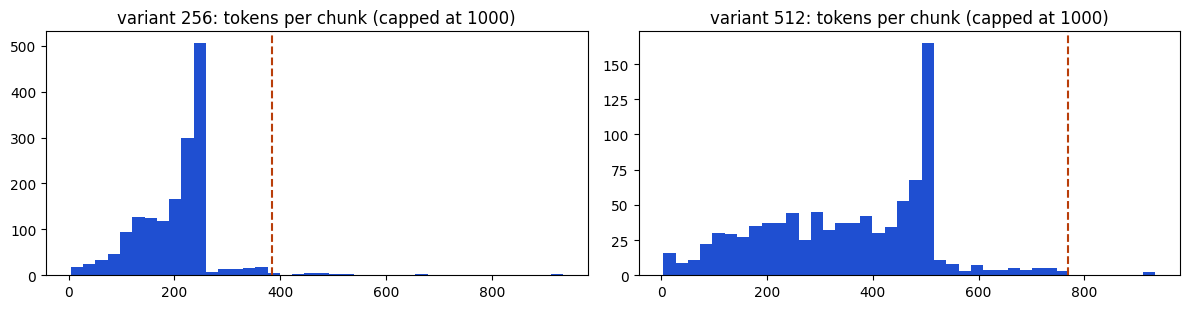

In [3]:
for v, cs in chunks.items():
    df = pd.DataFrame([{"id": c["chunk_id"], "type": c["source_type"], "pages": c["pages"],
                        "tokens": c["tokens"], "preview": c["text_en"][:90].replace("\n", " ")} for c in cs])
    print(f"=== variant {v} (limit {MAX_TOKENS[v]} tokens) ===")
    stats = df.groupby("type")["tokens"].describe()[["count", "min", "50%", "max"]].astype(int)
    stats["over_limit"] = (df["tokens"] > MAX_TOKENS[v]).groupby(df["type"]).sum()
    display(stats)
    tiny = df[df["tokens"] < 40].sort_values("tokens")
    print(f"chunks under 40 tokens: {len(tiny)}")
    display(tiny.head(15)[["id", "type", "pages", "tokens", "preview"]])

fig, axes = plt.subplots(1, len(chunks), figsize=(6 * len(chunks), 3.2), squeeze=False)
for ax, (v, cs) in zip(axes[0], chunks.items()):
    ax.hist([min(c["tokens"], 1000) for c in cs], bins=40, color="#1F4FD1")
    ax.axvline(MAX_TOKENS[v], color="#B93E0A", ls="--")
    ax.set_title(f"variant {v}: tokens per chunk (capped at 1000)")
plt.tight_layout(); plt.show()


### A3. Leftovers that would change a medical meaning
Looks for damage we already met once: symbols from the old Symbol font that were not decoded (they show up as invisible private-use characters, 592 of them on 69 pages of the raw PDF text), a lost micro sign (`3-5 g/kg/min` instead of `3-5 μg/kg/min`; plain `g/kg` doses such as mannitol are normal and are not flagged),
leftover LaTeX, and markdown links stuck inside numbers. All counts should be **0**.

In [4]:
PATTERNS = {
    "lost micro sign (digit then g/kg/min)": r"\d\s?g/kg/min",
    "undecoded Symbol-font character (private-use)": r"[\ue000-\uf8ff]",
    "leftover LaTeX": r"\\geq|\\leq|\$\w",
    "link bracket inside a number": r"\d\[\d",
}
for v, cs in chunks.items():
    print(f"=== variant {v} ===")
    for name, pat in PATTERNS.items():
        hits = [c for c in cs if re.search(pat, c["text_en"])]
        print(f"  {name}: {len(hits)}")
        for c in hits[:3]:
            m = re.search(pat, c["text_en"])
            print("     e.g.", c["chunk_id"], "...", c["text_en"][max(0, m.start()-30): m.end()+30].replace("\n", " "))
    print("  chunks that contain a micro sign (good sign):", sum(1 for c in cs if "μ" in c["text_en"]))


=== variant 256 ===
  lost micro sign (digit then g/kg/min): 0
  undecoded Symbol-font character (private-use): 0
  leftover LaTeX: 3
     e.g. s02_oxygen_therapy_and_respiratory_supports_0020 ... --| | Nominal content (m³): | $0.34  \text{m}^3$ | 0.68 m <sup
     e.g. s45_infectious_endocarditis_0033 ... vancomycin is recommended for $4\!-\!6$ weeks using the     | 
     e.g. s49_management_of_cardiovascular_diseases_du_0013 ... murmur,<br>diastolic murmur, \$4                              
  link bracket inside a number: 0
  chunks that contain a micro sign (good sign): 9
=== variant 512 ===
  lost micro sign (digit then g/kg/min): 0
  undecoded Symbol-font character (private-use): 0
  leftover LaTeX: 3
     e.g. s02_oxygen_therapy_and_respiratory_supports_0011 ... --| | Nominal content (m³): | $0.34  \text{m}^3$ | 0.68 m <sup
     e.g. s45_infectious_endocarditis_0020 ... vancomycin is recommended for $4\!-\!6$ weeks using the     | 
     e.g. s49_management_of_cardiovascular_diseas

### A4. Tables
Three things to look at:
1. tables whose numbers were **not verified** against the PDF text (they are pictures in the PDF): a person has to check these;
2. tables with no header separator row (a split table part that lost its header);
3. score tables whose header repeats the same number twice (`3 2 1 0 1 2 3`), which a search model cannot tell apart.

In [5]:
def header_has_repeated_numbers(text):
    for line in text.splitlines()[:3]:
        cells = [x.strip() for x in line.strip().strip("|").split("|")]
        nums = [x for x in cells[1:] if x]
        if len(nums) >= 4 and all(re.fullmatch(r"\d+", x) for x in nums) and len(set(nums)) < len(nums):
            return True
    return False

for v, cs in chunks.items():
    tb = [c for c in cs if c["source_type"] == "table"]
    unverified = [c for c in tb if not c.get("numbers_verified")]
    no_sep = [c for c in tb if not re.search(r"^\|[-| :]+\|\s*$", c["text_en"], flags=re.M)]
    dup_head = [c for c in tb if header_has_repeated_numbers(c["text_en"])]
    print(f"=== variant {v}: {len(tb)} table chunks ===")
    print(f"  numbers NOT verified (check by hand): {len(unverified)}")
    print(f"     pages: {sorted({p for c in unverified for p in c['pages']})}")
    print(f"  no header separator row: {len(no_sep)}", [c["chunk_id"] for c in no_sep[:5]])
    print(f"  header with repeated numbers: {len(dup_head)}", [c["chunk_id"] for c in dup_head[:5]])


=== variant 256: 286 table chunks ===
  numbers NOT verified (check by hand): 124
     pages: [17, 19, 34, 43, 44, 47, 159, 170, 252, 266, 298, 338, 353, 354, 379, 386, 411, 412, 413, 420, 421, 422, 423, 443, 452]
  no header separator row: 0 []
  header with repeated numbers: 2 ['s03_early_warning_score_in_hospital_0005', 's24_sepsis_and_septic_shock_empirical_antibi_0009']
=== variant 512: 185 table chunks ===
  numbers NOT verified (check by hand): 60
     pages: [17, 19, 34, 43, 44, 47, 159, 170, 252, 266, 298, 338, 353, 354, 379, 386, 411, 412, 413, 420, 421, 422, 423, 443, 452]
  no header separator row: 0 []
  header with repeated numbers: 2 ['s03_early_warning_score_in_hospital_0003', 's24_sepsis_and_septic_shock_empirical_antibi_0005']


### A5. Citation page vs printed page
The citation uses the **PDF page**. A nurse holding the printed guideline looks for the **printed page** (page 43 of the PDF is printed as page 30).
This cell shows how many citations point to a different number than the one printed on the page.

In [6]:
for v, cs in chunks.items():
    diff = 0
    example = None
    for c in cs:
        m = re.search(r"p\.\s*(\d+)", c.get("citation") or "")
        printed = (c.get("metadata") or {}).get("printed_pages")
        if m and printed and int(m.group(1)) not in printed:
            diff += 1
            example = example or (c["citation"], printed)
    print(f"variant {v}: {diff} of {len(cs)} citations differ from the printed page number. Example: {example}")


variant 256: 1652 of 1652 citations differ from the printed page number. Example: ('Ch. I §1 Assessment the Patients in Emergency Room, p. 17', [4])
variant 512: 926 of 926 citations differ from the printed page number. Example: ('Ch. I §1 Assessment the Patients in Emergency Room, p. 17', [4])


## Part B. Eyeball a sample
Prints a few random chunks of each type and shows the PDF page next to each one.
Look for: cut-off sentences, a table missing its header, a flowchart that lost a branch, text from two different topics glued together.
Change `SEED` or `VARIANT_TO_SHOW` to see others.

s06_stroke_syndrome_in_emergency_0012 | body_text | Ch. I §6 Stroke Syndrome in Emergency, p. 81 | 200 tokens | verified: True
----------------------------------------------------------------------------------------------------
4. Out-patient management
Only after assessment and treatment in acute phase, that patients who survived with variable handicaps may have outpatient management. The treatment focus on rehabilitation, most importantly during the first 3 months, and the Secondary prevention of cardiovascular disease.
5. First-line treatment
The management of Stroke syndrome consisted of early stabilization (SpO2> 94%, PaCO2: 35-40mmHg, SBP > 90mmHg, treat hypoglycemia, keep glycemia 140- 180mg/dl for hyperglycemic patient. Once the patient’s condition is stabilized, immediately send the patient for a non-contrast head CT
a) Supportive treatment
Supportive therapy for patients with Intracerebral vascular diseases (ICVD) should begin upon hospitalization.
Head of the bed elevated to

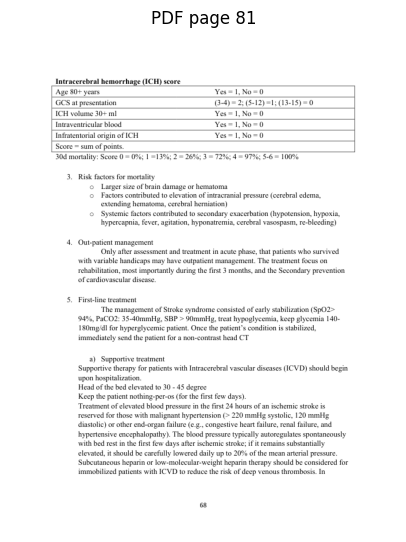

s25_severe_acute_respiratory_infection_sari__0011 | body_text | Ch. I §25 Severe Acute Respiratory infection (SARI) And Influenza, pp. 261–262 | 506 tokens | verified: True
----------------------------------------------------------------------------------------------------
High Flow nasal canula (HFNC): need specific machine, some ICU-ventilator have this function
Non-invasive ventilation (NIV): use ICU-ventilator, or standalone CPAP machine Mechanical ventilation: ICU-ventilator. Patient needs to be intubated. Antiviral drugs
- Mild to moderate cases: oseltamivir (Tamiflu) 75 mg PO BID for 5 days
- Severe cases: oseltamivir (Tamiflu) 150 mg BID for 7 to 10 days
- Postexposure prophylaxis: oseltamivir (Tamiflu) 75 mg PO once a day for 7 to 10 days
- Monitor for resistance; some H5N1 and H7N9 viruses show resistance to oseltamivir. Almost all patients with severe influenza in the ICU will have deficits in oxygenation, leading to acute respiratory distress syndrome (ARDS) and requiring v

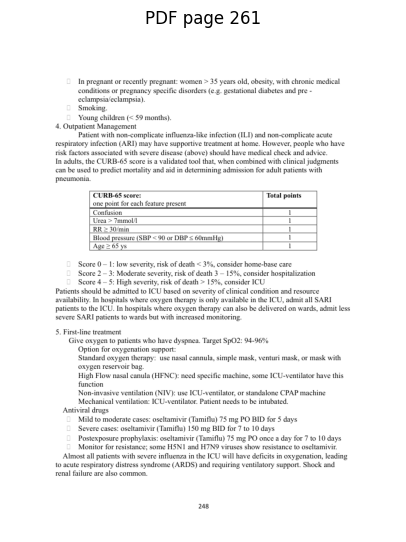

s43_deep_venous_thrombosis_0003 | body_text | Ch. II §43 Deep Venous Thrombosis, pp. 397–398 | 239 tokens | verified: True
----------------------------------------------------------------------------------------------------
## V. DIAGNOSIS
1. Clinical assessment:
- Assess symptoms (leg pain, swelling) and use a clinical prediction tool like the two-level modified Well’s Score (Annex 1) to determine the likelihood of DVT
2. D-dimer Test:
- For patients with DVT unlikely, a D-dimer blood test is performed. If the D-dimer is negative, DVT is ruled out. If positive, further imaging is required.
3. Imaging with Venous Ultrasound:
- For patients with DVT likely or positive D-dimer, compression venous ultrasound is the first-line imaging test.
4. Further Imaging:
- If the ultrasound results are unclear or DVT involves unusual locations (e.g. pelvic veins), advanced imaging like CT venography or MR venography may be used.
5. Follow-up:
- In patients where initial tests are inconclusive but sus

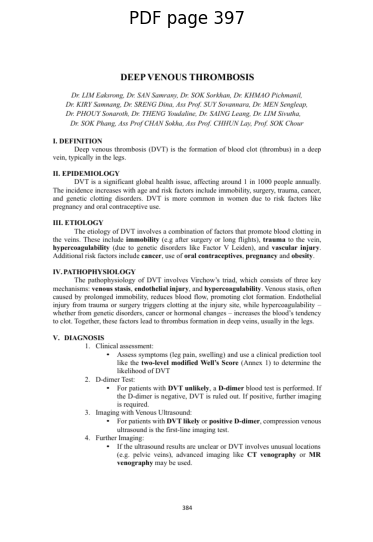

s04_shock_0017 | table | Ch. I §4 Shock, p. 56 | 399 tokens | verified: True
----------------------------------------------------------------------------------------------------
|  | Supportive Treatment | Etiologic Treatment |
|---|---|---|
| ▪ ▪ ▪ ▪ | O2: 6 - 10L/min (High flow oxygen mask) - Intubation-Ventilation? 2 larges caliber IV access (14 - 16 G) Passive leg raising above the level of the heart with the patient supine. Anti-shock pant Fluid therapy ▪ Crystalloids (RL, SSI) ▪ Colloids: Gelatins (Gelofusine), Dextrans, Albumin | Contemporary of the symptomatic treatment: ▪ Surgical procedure: goal to achieve hemostasis in aortic aneurysm rupture; gastrointestinal bleeding; open penetrating wound ▪ Medical procedure: |
| ▪ ▪ ▪ | the patient supine. Anti-shock pant Fluid therapy ▪ Crystalloids (RL, SSI) ▪ Colloids: Gelatins (Gelofusine), Dextrans, Albumin If no response to fluids (SBP < 80 mmHg and MAP < 60 mmHg): Norepinephrine starts 5 mcg/min IV Blood products: ▪ Packed red bl

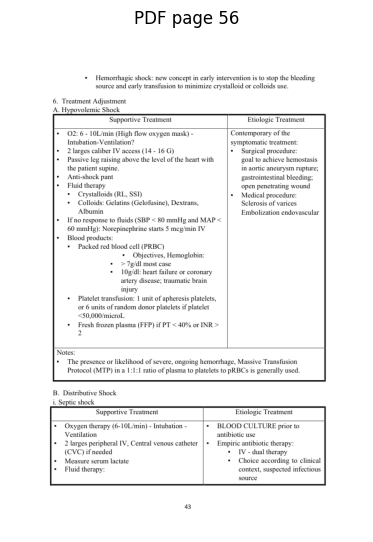

s28_acute_coronary_syndrome_st_elevation_myo_0005 | table | Ch. II §28 Acute Coronary Syndrome St-elevation Myocardial Infarction (STEMI), p. 286 | 365 tokens | verified: True
----------------------------------------------------------------------------------------------------
| Cardiac disease | Pulmonary disease | Macrovascular<br>disease | Digestive disease | Orthopedic disease | Other |
|---|---|---|---|---|---|
| Myocarditis | Acute pulmonary<br>thromboembolism | Acute aortic<br>dissection | Reflux esophagitis | Chest trauma | Anxiety attack |
| Pericarditis | Pneumothorax | Symptomatic aortic<br>aneurysm | Esophageal spasm | Skeletal muscle<br>disorder | Herpes Zoster |
| Acute heart failure | Bronchitis,<br>pneumonia | Stroke | Peptic ulcer,<br>gastritis | Costochondritis | Anemia |
| Hypertensive<br>emergency | Pleurisy |  | Pancreatitis | Cervical disc<br>disease | Pyrexia |
| Aortic stenosis |  |  | Cholecystitis<br>gallstone | Intercostal neuralgia | Hyperthyroidism |
| Takot

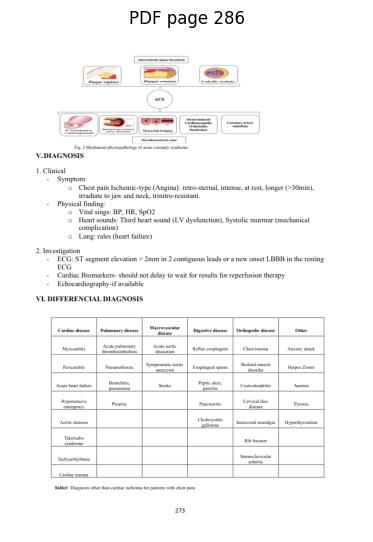

s08_allergic_reaction_0007 | table | Ch. I §8 Allergic Reaction, p. 102 | 372 tokens | verified: True
----------------------------------------------------------------------------------------------------
| Differential Diagnosis of Anaphylaxis |  |
|---|---|
| Acute generalized urticarial | Shock Syndromes |
| Asthma exacerbation | Septic shock |
| Myocardial infarction | Hypovolemic shock |
| Pulmonary embolus | Cardiogenic shock |
| Syncope | Distributive shock |
| Adverse cutaneous drug reaction |  |
| Anxiety/panic attacks | Miscellaneous |
| Flush Syndrome | Hypoglycemia Acquired and |
| Flushing associated with food | Acquired and HAE ACE-inhibitor- |
| Alcohol | associated |
| MSG | angioedema |
| Sulfites | Red man syndrome (Vancomycin) |
| Scombroidosis | Neurologic disorders (seizure, stroke, |
| Carcinoid tumor Peri- | autonomic epilepsy) |
| menopause | Vocal cord dysfunction syndrome |
| Thyrotoxicosis | Pheochromocytoma |
| Basophilic leukemia |  |
| Mastocytosis (systemic

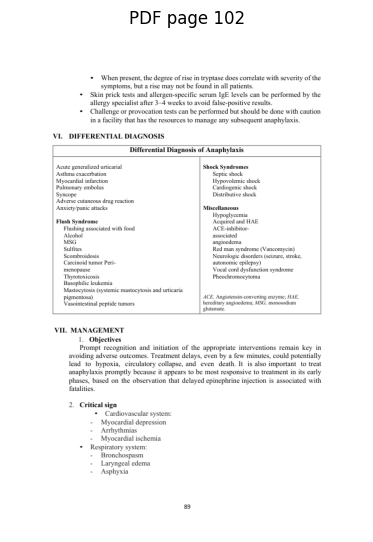

s29_acute_coronary_syndrome_acs_non_st_eleva_0022 | flowchart | Ch. II §29 Acute Coronary Syndrome (ACS)NON-ST Elevation Myocardial Infarction (NSTEMI), p. 299 | 430 tokens | verified: False
----------------------------------------------------------------------------------------------------
## 7. Algorithm

Symptoms of acute coronary syndrome

- Obtain serial EKG, Serial Troponin and Chest X-ray

- Focused history and physical exam

- Assess vitals

- Obtain IV access

Obtain serial EKG, Serial Troponin and Chest X-ray leads to:

- ST depression

- T wave inversion

- Normal

ST depression and T wave inversion lead to NSTEMI (troponin +).

Normal leads to Unstable Angina (troponin -).

Immediate medical therapy upon diagnosis of NSTEMI/UA

- Aspirin 250mg (Load)

- P2YQ12 inhibitor load (Consider delaying if coronary anatomy not known and early invasive management planned)

- Anticoagulant

This leads to risk stratification:

| Very High risk | High risk | Intermediate risk | Low risk 

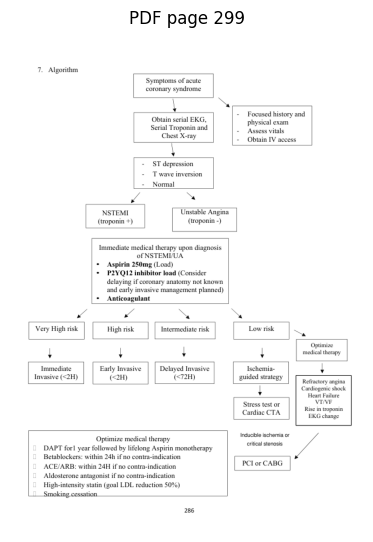

s38_aortic_stenosis_as_0011 | figure | Ch. II §38 Aortic Stenosis (AS), p. 370 | 459 tokens | verified: False
----------------------------------------------------------------------------------------------------
This is a clinical decision-making algorithm titled “Management of patients with severe aortic stenosis.” It outlines a stepwise approach to determine appropriate interventions based on patient characteristics.

---

**Decision Points and Branches:**

1. **Initial Decision Point: Symptoms**
   - If YES (Y) → Proceed to assess if intervention is likely beneficial after evaluating comorbidity and frailty.
     - If YES (Y) → Intervention (SAVR or TAVI) is indicated.
     - If NO (N) → Medical therapy.
   - If NO (N) → Assess LVEF (<50%).

2. **LVEF < 50%?**
   - If YES (Y) → Proceed to assess physical activity status.
   - If NO (N) → Proceed to assess physical activity status.

3. **Physically active?**
   - If YES (Y) → Perform exercise test.
   - If NO (N) → Proceed to assess i

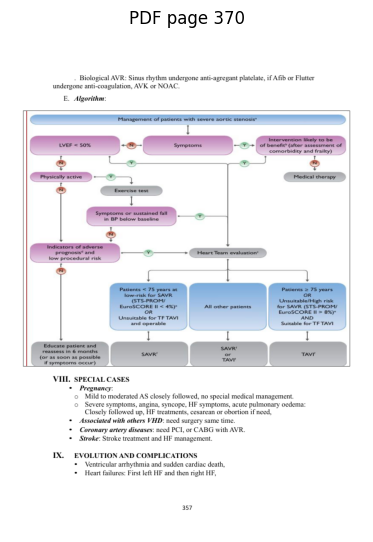

In [7]:
import fitz                                      # imported here on purpose, after torch (see top cell)
from PIL import Image

VARIANT_TO_SHOW = "512"
SEED = 1
PER_TYPE = {"body_text": 3, "table": 3, "flowchart": 1, "figure": 1}

doc = fitz.open(PDF_PATH)
def page_image(page_no, zoom=1.1):
    pix = doc[page_no - 1].get_pixmap(matrix=fitz.Matrix(zoom, zoom))
    return Image.frombytes("RGB", [pix.width, pix.height], pix.samples)

def show_chunk(c):
    print("=" * 100)
    print(c["chunk_id"], "|", c["source_type"], "|", c["citation"], "|", c["tokens"], "tokens | verified:", c.get("numbers_verified"))
    print("-" * 100)
    print(c["text_en"][:1200] + (" ..." if len(c["text_en"]) > 1200 else ""))
    plt.figure(figsize=(5, 6.5)); plt.imshow(page_image(c["pages"][0])); plt.axis("off")
    plt.title(f"PDF page {c['pages'][0]}"); plt.show()

rng = random.Random(SEED)
pool = chunks[VARIANT_TO_SHOW]
for t, n in PER_TYPE.items():
    candidates = [c for c in pool if c["source_type"] == t]
    for c in rng.sample(candidates, min(n, len(candidates))):
        show_chunk(c)


## Part C. Search test (20 questions)
Each question has the page(s) that hold the answer and a **phrase that must appear** in the retrieved chunk.
A chunk counts as a hit only if it covers one of those pages **and** contains the phrase.
That way the test does not care where the chunk borders are.

Two of the questions ask about the NEWS-2 table, which is a **picture** in the PDF, so they test the image-table path.
There are no flowchart questions yet; add some if flowcharts matter for the demo.

In [8]:
GOLD = [
 # id, kind, question, pages holding the answer, phrases that must appear in the chunk
 ("hob", "text", "At what angle should the head of the bed be raised in patients with intracerebral haemorrhage?", [81, 96], ["head of the bed", "45 degree"]),
 ("norepi", "text", "In shock that does not respond to fluids, when is norepinephrine started and at what dose?", [56], ["norepinephrine starts 5 mcg/min"]),
 ("nac", "text", "What is the antidote for paracetamol poisoning?", [125], ["paracetamol antidote"]),
 ("dobu_shock", "text", "What is the dose range of dobutamine as a vasopressor in shock?", [57], ["dobutamine: 2-20 mcg/kg/min"]),
 ("ca_gluc", "text", "How is hyperkalemia treated first with calcium gluconate?", [218], ["calcium gluconate iv 1,000 mg"]),
 ("insulin_k", "text", "What insulin dose helps move potassium into cells in hyperkalemia?", [218], ["insulin 10 u iv"]),
 ("hyponatremia", "text", "How should acute hyponatremia be treated and how fast can sodium be raised?", [95], ["3% hypertonic saline", "8-10"]),
 ("qsofa", "text", "What are the qSOFA criteria for sepsis outside the ICU?", [43], ["qsofa", "altered mental status"]),
 ("spo2_scale2", "text", "What oxygen saturation range is targeted in COPD patients when using NEWS-2 scale 2?", [43], ["88-92%"]),
 ("antivenom", "text", "Do I need to wait for lab results before starting antivenom?", [271], ["no need to wait for lab test results"]),
 ("snake_exposure", "text", "What should be done in the exposure step if a snake bite is suspected?", [29], ["immobilize the limb"]),
 ("cobra", "table", "What is the Latin name of the monocellate cobra in Cambodia?", [266], ["naja kaouthia", "monocellate cobra"]),
 ("pe_duration", "text", "How long should anticoagulation last after a provoked pulmonary embolism?", [323], ["provoked pe", "months of anticoagulation"]),
 ("platelets", "text", "What platelet count should be maintained when giving platelets in bleeding?", [74], ["platelet count above 50"]),
 ("kcl_central", "text", "When is a central line recommended for potassium replacement?", [228], ["central line is recommended for rate >10 meq/hr"]),
 ("triage3", "text", "How quickly must a Triage Level III patient be assessed?", [18], ["within 30 minutes of arrival"]),
 ("anaph", "text", "What is the first drug in anaphylaxis and how is it given?", [103], ["intramuscular (im) injection of epinephrine"]),
 ("dobu_hf", "text", "What dobutamine dose is used for cold and wet heart failure with low blood pressure?", [329], ["dobutamine= 3-5"]),
 ("spo2_scale1", "image_table", "What is the NEWS-2 score 3 threshold for SpO2 on scale 1?", [43], ["spo2 scale 1", "≤91"]),
 ("news_agg7", "image_table", "What response does a NEWS-2 aggregate score of 7 or more need?", [43], ["aggregate score 7"]),
]

def norm(s):
    """Lower case, one kind of dash, no table pipes, single spaces."""
    s = s.lower()
    s = re.sub(r"[–—−]", "-", s)
    s = s.replace("<br>", " ").replace("|", " ")
    return re.sub(r"\s+", " ", s)

def page_set(c):
    return set(range(min(c["pages"]), max(c["pages"]) + 1))

def is_relevant(c, gold_pages, must):
    return bool(page_set(c) & set(gold_pages)) and all(norm(m) in norm(c["text_en"]) for m in must)


In [9]:
model = SentenceTransformer("BAAI/bge-m3")      # already in the cache, no download
model.max_seq_length = 1024

def run_retrieval(cs):
    texts = [c.get("embed_text_en") or c["text_en"] for c in cs]
    chunk_vecs = model.encode(texts, batch_size=16, normalize_embeddings=True, show_progress_bar=False)
    query_vecs = model.encode([g[2] for g in GOLD], normalize_embeddings=True, show_progress_bar=False)
    sims = query_vecs @ chunk_vecs.T                      # cosine similarity, queries x chunks
    out = []
    for i, (gid, kind, q, pages, must) in enumerate(GOLD):
        relevant = np.array([is_relevant(c, pages, must) for c in cs])
        order = np.argsort(-sims[i])
        rank = None
        if relevant.any():
            rank = int(np.argmax(relevant[order])) + 1    # position of the first relevant chunk
        out.append({"id": gid, "kind": kind, "rank": rank, "n_relevant_chunks": int(relevant.sum()),
                    "top3": [(cs[j]["chunk_id"], cs[j]["pages"]) for j in order[:3]]})
    return pd.DataFrame(out)

results = {v: run_retrieval(cs) for v, cs in chunks.items()}

def summarize(df):
    r = df["rank"]
    return {
        "Hit@1": round((r == 1).mean(), 2), "Hit@3": round((r <= 3).mean(), 2), "Hit@5": round((r <= 5).mean(), 2),
        "MRR@10": round(np.mean([1 / x if (x and x <= 10) else 0 for x in r]), 3),
        "no relevant chunk exists": int((df["n_relevant_chunks"] == 0).sum()),
    }

summary = pd.DataFrame({v: summarize(df) for v, df in results.items()}).T
summary["no relevant chunk exists"] = summary["no relevant chunk exists"].astype(int)
display(summary)


,Hit@1,Hit@3,Hit@5,MRR@10,no relevant chunk exists
256,0.45,0.65,0.70,0.586,0
512,0.50,0.65,0.75,0.622,0


--- variant 256 ---


/tmp/ipykernel_49/3809062935.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_kind = df.groupby("kind").apply(lambda g: pd.Series({"questions": len(g), "Hit@1": round((g["rank"] == 1).mean(), 2),


,questions,Hit@1,Hit@5
kind,,,
image_table,2.0,0.00,0.50
table,1.0,1.00,1.00
text,17.0,0.47,0.71


--- variant 512 ---


/tmp/ipykernel_49/3809062935.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_kind = df.groupby("kind").apply(lambda g: pd.Series({"questions": len(g), "Hit@1": round((g["rank"] == 1).mean(), 2),


,questions,Hit@1,Hit@5
kind,,,
image_table,2.0,0.00,0.50
table,1.0,1.00,1.00
text,17.0,0.53,0.76


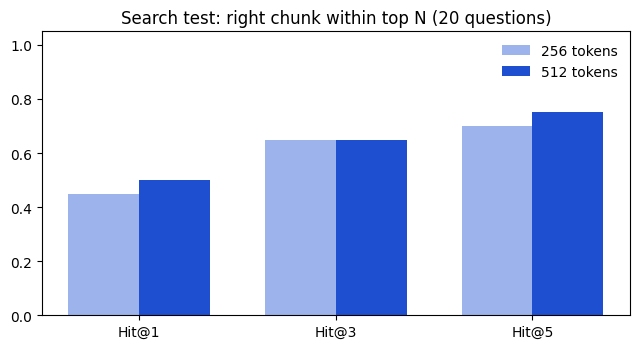

In [10]:
# By kind of content, and a chart of the two variants.
for v, df in results.items():
    by_kind = df.groupby("kind").apply(lambda g: pd.Series({"questions": len(g), "Hit@1": round((g["rank"] == 1).mean(), 2),
                                                             "Hit@5": round((g["rank"] <= 5).mean(), 2)}))
    print(f"--- variant {v} ---"); display(by_kind)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(3); w = 0.36
for k, (v, color) in enumerate(zip(results.keys(), ["#9DB3EC", "#1F4FD1"])):
    vals = [summary.loc[v, m] for m in ["Hit@1", "Hit@3", "Hit@5"]]
    ax.bar(x + (k - 0.5) * w, vals, w, color=color, label=f"{v} tokens")
ax.set_xticks(x); ax.set_xticklabels(["Hit@1", "Hit@3", "Hit@5"]); ax.set_ylim(0, 1.05); ax.legend(frameon=False)
ax.set_title("Search test: right chunk within top N (20 questions)")
plt.tight_layout(); plt.show()


### What went wrong? (misses)
For each question that is **not** in the top 3, this shows what came back instead.
Read the column `n_relevant_chunks` first:
- **0** means the answer text is not in any chunk with that phrase and page. That is a **chunking or extraction problem**, not a search problem.
- **1 or more** means the answer is in the index but ranked low. That is a **search problem**.

In [11]:
for v, df in results.items():
    miss = df[(df["rank"].isna()) | (df["rank"] > 3)]
    print(f"=== variant {v}: {len(miss)} questions outside the top 3 ===")
    for _, r in miss.iterrows():
        g = next(g for g in GOLD if g[0] == r["id"])
        print(f"* [{r['kind']}] {g[2]}")
        print(f"    expected pages {g[3]}, rank {r['rank']}, relevant chunks in index: {r['n_relevant_chunks']}")
        print(f"    got instead: {r['top3']}")


=== variant 256: 7 questions outside the top 3 ===
* [text] What is the dose range of dobutamine as a vasopressor in shock?
    expected pages [57], rank 9, relevant chunks in index: 1
    got instead: [('s04_shock_0026', [55, 56]), ('s04_shock_0012', [51]), ('s04_shock_0020', [53])]
* [text] What insulin dose helps move potassium into cells in hyperkalemia?
    expected pages [218], rank 14, relevant chunks in index: 1
    got instead: [('s21_hypokalemia_0020', [228]), ('s21_hypokalemia_0028', [228, 229, 230]), ('s21_hypokalemia_0019', [228])]
* [text] What should be done in the exposure step if a snake bite is suspected?
    expected pages [29], rank 6, relevant chunks in index: 1
    got instead: [('s26_snake_bites_0038', [275]), ('s26_snake_bites_0021', [271]), ('s26_snake_bites_0028', [272, 273])]
* [text] What is the first drug in anaphylaxis and how is it given?
    expected pages [103], rank 13, relevant chunks in index: 1
    got instead: [('s08_allergic_reaction_0016', [103])

## How to read the result

| What you see | What it means | What to do |
|---|---|---|
| A1 columns not all 0 | schema problem | fix before anything else |
| A2: many tiny chunks | headings or fragments in the index | merge them into the next chunk, or exclude them |
| A3: any count above 0 | a medical meaning may have changed | find the chunk and fix the source |
| A4: unverified tables | numbers nobody has compared with the page | give the page list to a person to check |
| A4: repeated header numbers | score columns cannot be told apart | rename the header, e.g. `Score 3 (low)` and `Score 3 (high)` |
| A5: many differences | users will look up the wrong page | switch the citation to the printed page |
| C: misses with 0 relevant chunks | answer missing from the chunks | look at that page in Part B |
| C: misses with relevant chunks | ranking problem | compare 256 vs 512, then test on the question bank |

Both variants passing the audit and scoring close to each other is the expected outcome.
The choice between 256 and 512 should be made on the question bank, not on 20 questions.
